[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/xylem-lab/GEO-ANOM-dashboard/blob/task1/final-2026-11-03/notebooks/11_task1_final_map.ipynb)

# 11 — Task 1 final map: from the published model to the frozen map, one step at a time

**Question.** How much does each improvement add over the published model (Robinson et al. 2022), and what is the final map we freeze for Task 2?

**How.** Every step is rebuilt from the result folders on the shared drive and scored the same way against the USGS hand-traced poultry houses (Soroka & Duren 2020, 2016/17), inside the area USGS traced:

| step | what it adds | why |
|---|---|---|
| 0 published model | Robinson U-Net + Tulbure shape filter, notebook 05 | the baseline |
| 1 rectangle outlines | each outline → its minimum rotated rectangle | the U-Net covers ~78% of a roof; a rectangle ~97% |
| 2 brightened photo | the two darkest 2023 flights rerun, tone-matched to 2021 (notebook 08) | 2023 photos are darker; most misses were on them |
| 3 SAM repair | rejected short pieces / merged blobs grown or split into whole houses by Segment Anything, kept only if house-shaped | 278 misses were short pieces, 65 merged neighbours |
| 4 checked by eye | detections called *not poultry* in notebook 07 dropped; houses confirmed by eye that only the fine-tuned model found added | the human check |

Steps 1–3 reproduce **final map v1** (2,823 houses). Step 4 is the **frozen map** that Task 2 reads.

**Tested, scored the same way, not adopted:** the road rule (outlines with their centre < 20 m from an OpenStreetMap road dropped; the Tulbure rule, off until now) and the fine-tuned model (notebook 10).

- *found* = traced houses touched by an outline; *recall* = found / traced.
- *precision vs tracing* = outlines touching a traced house / outlines (inside the traced area). New houses built after 2016/17 count as wrong here, so it is a floor.
- *precision checked* = the same, but outlines on a house confirmed by eye in notebook 07 count as right.
- *cover* = median share of a traced roof covered by its outline (roof area is what Task 2 uses).

Laptop is enough. The SAM step runs once (~30 min on CPU) and is saved; later runs reuse it.

In [1]:
# ── Setup: the same cell works in Google Colab and locally ──────────────────────
import os, sys, json, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
CODE_VERSION = "task1/final-2026-11-03"   # branch, tag or commit to run; the exact commit is recorded in run_meta.json

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")                     # results go to the shared drive's Task1_results
    ROOT = Path("/content/GEO-ANOM-dashboard")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/xylem-lab/GEO-ANOM-dashboard", str(ROOT)], check=True)
    # always bring the copy up to date (a reused Colab session keeps an old copy)
    head = lambda: subprocess.run(["git", "-C", str(ROOT), "rev-parse", "HEAD"], capture_output=True, text=True).stdout
    before = head()
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin"], check=True)
    remote = f"origin/{CODE_VERSION}"
    target = remote if subprocess.run(["git", "-C", str(ROOT), "rev-parse", "-q", "--verify", remote],
                                      capture_output=True).returncode == 0 else CODE_VERSION
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "--detach", target], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements-colab.txt")], check=True)
    if head() != before and "geo_anom" in sys.modules:   # new code, but the old version is already loaded
        raise RuntimeError("Code updated. Runtime -> Restart session, then Run all again.")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline
# reload edited geo_anom/ code automatically, without restarting the kernel
if "google.colab" not in sys.modules:   # Colab's IPython can't load autoreload on Python 3.12+ (no `imp`)
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100)

from geo_anom.task1 import env, region
from geo_anom.task1 import county as C
from geo_anom.task1 import final as FN
from geo_anom.task1 import training as T
from geo_anom.task1.evaluate import load_ground_truth
from geo_anom.task1.pipeline import git_commit
print("running in", "Colab" if IN_COLAB else "local", "| results ->", env.results_root())

running in local | results -> /Users/umeshadari/Library/CloudStorage/GoogleDrive-umeshka@umd.edu/Shared drives/AIM-GEO-ANOM/Task1_results


## Settings

In [2]:
FINAL = FN.final_dir()                                           # Task1_results/final
SAM_DIR = FINAL / "sam_repair"                                   # SAM shapes (made once, reused)
BRIGHT = env.results_root() / "experiments" / "tone_match_2021"  # notebook 08 runs
REVIEW = env.results_root() / "review"                           # notebook 07 labels
ROAD_CACHE = env.results_root() / "reference" / "osm_roads"      # OpenStreetMap roads, downloaded once
RELEASE = FINAL / "release_v1"                                   # the frozen map (shared drive only: house locations)
COUNTIES = C.EASTERN_SHORE
print("final ->", FINAL)

final -> /Users/umeshadari/Library/CloudStorage/GoogleDrive-umeshka@umd.edu/Shared drives/AIM-GEO-ANOM/Task1_results/final


## 1. SAM repair (once)

Short rejected pieces (10–55 m long) and blobs too big or wide for one house, from every Eastern Shore run; SAM grows each piece into the roof it belongs to, or splits a blob into houses, on the same 2023 photo. Resumable: rerunning continues where it stopped, and does nothing once every window is done.

In [3]:
done = (SAM_DIR / "done_cells.txt").read_text().split() if (SAM_DIR / "done_cells.txt").exists() else []
pieces = FN.sam_pieces(COUNTIES)
todo = set(pieces.cell) - set(done)
if todo:
    ckpt = ROOT / "data/models/sam_vit_b_01ec64.pth"
    if IN_COLAB:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "segment-anything"], check=True)
        if not ckpt.exists():
            ckpt.parent.mkdir(parents=True, exist_ok=True)
            subprocess.run(["wget", "-q", "-O", str(ckpt), "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"], check=True)
    FN.sam_recover(SAM_DIR, COUNTIES)
sam = FN.load_sam(SAM_DIR / "recovered.jsonl")
n_all = sum(1 for _ in open(SAM_DIR / "recovered.jsonl"))
print(f"{len(pieces)} pieces in {pieces.cell.nunique()} windows -> {n_all} SAM shapes, {len(sam)} pass the house rule {FN.SAM_RULE}")

1078 pieces in 711 windows -> 762 SAM shapes, 534 pass the house rule {'length_min': 80.0, 'width_max': 25.0, 'aspect_min': 5.0}


## 2. Labels checked by eye (notebook 07)

- sections 2–3: detections of the published model (Eastern Shore detections missing from the tracing, western detections, blind controls);
- section 7: detections only the fine-tuned model made (notebook 10), roads left out.

*Confirmed* = every reviewer said poultry house; *rejected* = every reviewer said not poultry.

In [4]:
conf07, rej07, _ = T.review_polygons(REVIEW, C.all_counties_in_order())
read = lambda f: gpd.read_file(f).to_crs(FN.UTM)[["geometry"]] if f.exists() else gpd.GeoDataFrame(geometry=[], crs=FN.UTM)
conf_ft, rej_ft = read(REVIEW / "finetune_v1" / "confirmed.geojson"), read(REVIEW / "finetune_v1" / "rejected.geojson")
cat = lambda *g: gpd.GeoDataFrame(pd.concat([x[["geometry"]] for x in g], ignore_index=True), crs=FN.UTM)
confirmed, rejected = cat(conf07, conf_ft), cat(rej07, rej_ft)
print(f"confirmed: {len(conf07)} (07) + {len(conf_ft)} (07 section 7) | rejected: {len(rej07)} + {len(rej_ft)}")

confirmed: 311 (07) + 14 (07 section 7) | rejected: 389 + 84


## 3. The ladder

In [5]:
gt = load_ground_truth().to_crs(FN.UTM).reset_index(drop=True)
layers = {n: FN.build_steps(n, sam, BRIGHT, ROAD_CACHE, rejected=rejected, confirmed_new=conf_ft) for n in COUNTIES}
lad = FN.ladder(layers, gt, confirmed)
es_all = lad[lad.county == "Eastern Shore"].set_index("step")
es = es_all.loc[FN.STEPS]
show = ["houses", "roof_km2", "traced", "found", "recall", "detections", "precision_vs_tracing", "precision_checked", "cover"]
display(Markdown("**Eastern Shore** (recall and precision inside the traced area; houses and roof for the whole Eastern Shore)"))
display(es[show].round(3))
display(Markdown("**Tested, not adopted** (on top of step 3)")); display(es_all.loc[[s for s in FN.TESTED if s in es_all.index], show].round(3))
v1 = int(es.loc["SAM repair", "houses"])
print(f"reproduces final map v1: {v1} houses (v1 had 2,823)")

**Eastern Shore** (recall and precision inside the traced area; houses and roof for the whole Eastern Shore)

,houses,roof_km2,traced,found,recall,detections,precision_vs_tracing,precision_checked,cover
step,,,,,,,,,
published model,2329,4.854,3040,2038,0.670,2300,0.888,0.990,0.792
rectangle outlines,2329,5.970,3040,2039,0.671,2300,0.888,0.990,0.911
brightened photo,2628,6.451,3040,2300,0.757,2597,0.887,0.977,0.911
SAM repair,2823,6.934,3040,2446,0.805,2780,0.881,0.965,0.917
checked by eye,2807,6.906,3040,2446,0.805,2777,0.882,0.970,0.917


**Tested, not adopted** (on top of step 3)

,houses,roof_km2,traced,found,recall,detections,precision_vs_tracing,precision_checked,cover
step,,,,,,,,,
road rule (not adopted),2810,6.916,3040,2438,0.802,2768,0.882,0.966,0.917


reproduces final map v1: 2823 houses (v1 had 2,823)


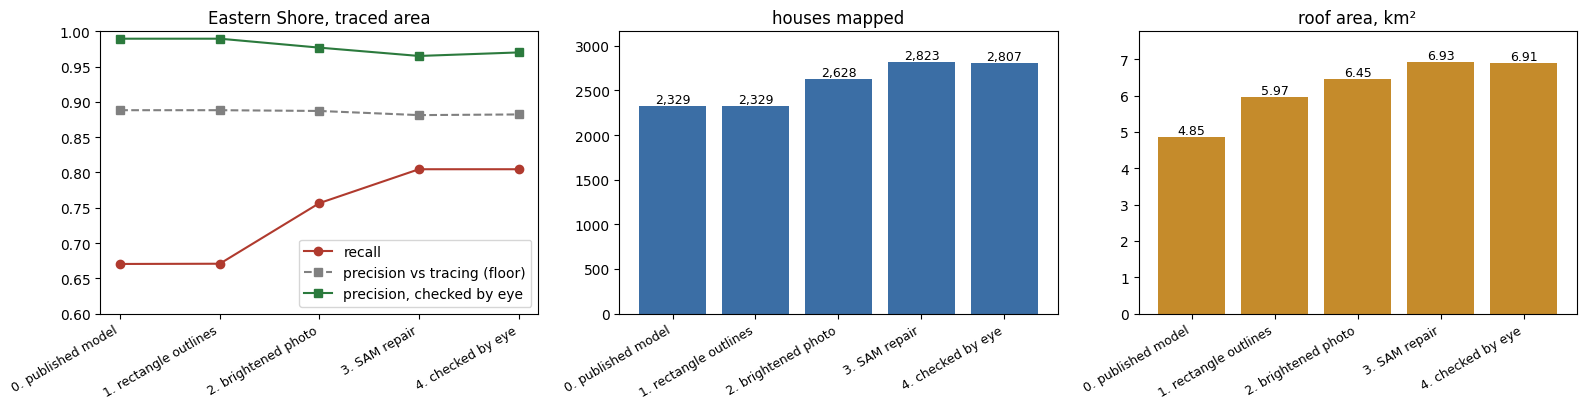

**Recall by county and step**

step,published model,rectangle outlines,brightened photo,SAM repair,checked by eye
county,,,,,
Caroline,0.80,0.80,0.82,0.89,0.89
Cecil,0.75,0.75,0.75,0.85,0.85
Dorchester,0.73,0.73,0.80,0.86,0.86
Kent,0.79,0.79,0.79,0.83,0.83
Queen Anne's,0.80,0.80,0.80,0.83,0.83
Somerset,0.66,0.66,0.75,0.78,0.78
Talbot,0.67,0.67,0.67,0.77,0.77
Wicomico,0.59,0.59,0.74,0.78,0.78
Worcester,0.58,0.58,0.70,0.75,0.75


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(len(FN.STEPS)); lab = [f"{i}. {s}" for i, s in enumerate(FN.STEPS)]
ax[0].plot(x, es.recall, "o-", color="#b03a2e", label="recall")
ax[0].plot(x, es.precision_vs_tracing, "s--", color="0.5", label="precision vs tracing (floor)")
ax[0].plot(x, es.precision_checked, "s-", color="#2b7a3d", label="precision, checked by eye")
ax[0].set_ylim(0.6, 1.0); ax[0].legend(loc="lower right"); ax[0].set_title("Eastern Shore, traced area")
ax[1].bar(x, es.houses, color="#3b6ea5"); ax[1].set_title("houses mapped")
for i, v in enumerate(es.houses): ax[1].text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=9)
ax[2].bar(x, es.roof_km2, color="#c58b2b"); ax[2].set_title("roof area, km²")
for i, v in enumerate(es.roof_km2): ax[2].text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
for a in ax: a.set_xticks(x); a.set_xticklabels(lab, rotation=30, ha="right", fontsize=9)
ax[1].set_ylim(0, es.houses.max() * 1.12); ax[2].set_ylim(0, es.roof_km2.max() * 1.12)
plt.tight_layout(); plt.show()
by = lad[lad.county != "Eastern Shore"].pivot(index="county", columns="step", values="recall")[FN.STEPS]
display(Markdown("**Recall by county and step**")); display(by.round(2))

### Is the SAM shape rule fair?

The rule in use (≥ 80 m long, ≤ 25 m wide, aspect ≥ 5) was chosen looking at the whole tracing, so its gain could be partly tuning. Test: split the Eastern Shore in two halves, pick the best rule (F1 of recall and precision checked by eye, over 75 rules) on one half, score it on the other, and swap.

In [7]:
sam_all = FN.load_sam(SAM_DIR / "recovered.jsonl", rule=None)
rule_scores = FN.sam_rule_scores(sam_all, BRIGHT, gt, confirmed)          # ~4 min
cv = FN.cross_validate_rule(rule_scores)
cv.to_csv(FINAL / "sam_rule_cross_check.csv", index=False)
display(cv.round(3))

,test fold,rule from,rule,recall,precision_checked,f1,found
0,"B: Wicomico, Somerset, Queen Anne's, Talbot",no SAM,no SAM,0.751,0.975,0.848,1113
1,"B: Wicomico, Somerset, Queen Anne's, Talbot",chosen on fold A,L>=60 W<=30 A>=5,0.789,0.960,0.866,1170
2,"B: Wicomico, Somerset, Queen Anne's, Talbot",rule in use,L>=80 W<=25 A>=5,0.786,0.961,0.864,1165
3,"B: Wicomico, Somerset, Queen Anne's, Talbot",best on test fold (hindsight),L>=60 W<=30 A>=4,0.792,0.956,0.866,1175
4,"A: Worcester, Caroline, Dorchester, Kent, Cecil",no SAM,no SAM,0.762,0.979,0.857,1187
5,"A: Worcester, Caroline, Dorchester, Kent, Cecil",chosen on fold B,L>=60 W<=30 A>=4,0.825,0.958,0.887,1285
6,"A: Worcester, Caroline, Dorchester, Kent, Cecil",rule in use,L>=80 W<=25 A>=5,0.823,0.969,0.890,1281
7,"A: Worcester, Caroline, Dorchester, Kent, Cecil",best on test fold (hindsight),L>=60 W<=30 A>=5,0.825,0.966,0.890,1285


## 4. Tested and not adopted

**Road rule** (table above): on this map it removes real houses built close to a road and hardly changes precision — the published model doesn't mark roads, so the rule has nothing to fix. It stays for the fine-tuned model only.

**Fine-tuned model (notebook 10).** Fine-tuned on 09's data, tested on two counties it never saw (Wicomico, Queen Anne's), road rule on, its own new detections checked by eye in 07 section 7. It found as many traced houses as the final map in one pass but with lower precision, so it failed the rule set before the test. Its 14 confirmed houses are kept (step 4).

In [8]:
cmp_f = env.results_root() / "experiments" / "finetune_v1" / "comparison.csv"
if cmp_f.exists():
    cmp = pd.read_csv(cmp_f)
    tot = cmp.groupby("model")[["traced", "detections", "found", "real", "wrong", "unchecked"]].sum()
    tot["recall"] = tot.found / tot.traced
    tot["precision_low"], tot["precision_high"] = tot.real / tot.detections, (tot.real + tot.unchecked) / tot.detections
    display(tot.loc[[m for m in ["published model", "final map v1", "fine-tuned"] if m in tot.index]].round(3))

,traced,detections,found,real,wrong,unchecked,recall,precision_low,precision_high
model,,,,,,,,,
published model,834,664,537,656,4,4,0.644,0.988,0.994
final map v1,834,811,659,776,4,31,0.790,0.957,0.995
fine-tuned,834,892,656,787,87,18,0.787,0.882,0.902


## 5. West of the Bay

No USGS tracing there. Extension says there are almost no poultry houses west of the Bay; notebook 07 agrees: of 417 western detections, the reviewer confirmed the few that are poultry houses. Those confirmed ones are added to the map as checked by eye.

In [9]:
west = conf07[~conf07.centroid.within(gpd.GeoSeries(
    [region.county_boundary(n).to_crs(FN.UTM).unary_union for n in COUNTIES], crs=FN.UTM).unary_union)].copy()
md = region.md_counties().to_crs(FN.UTM)
west = gpd.sjoin(west, md[["NAME", "geometry"]], predicate="within").rename(columns={"NAME": "county"})
west = FN.rect(west[["county", "geometry"]]).assign(source="checked by eye (west of the Bay)")
display(west.county.value_counts().rename("confirmed poultry houses").to_frame())

,confirmed poultry houses
county,
Frederick,21
Carroll,2
Washington,2
Harford,1


## 6. Freeze

The final map = step 4 on the Eastern Shore + the confirmed houses west of the Bay. Written to the shared drive only (house locations): the map, a county table, the ladder, and `MANIFEST.json` with the SHA-256 of every file, the code version and the inputs. **These numbers do not change after this**; a better map later is v2, made by rerunning the notebooks.

In [10]:
RELEASE.mkdir(parents=True, exist_ok=True)
es_final = pd.concat([layers[n]["checked by eye"] for n in COUNTIES], ignore_index=True)
final = gpd.GeoDataFrame(pd.concat([es_final, west], ignore_index=True), crs=FN.UTM)
final["roof_m2"] = final.geometry.area.round(1)
c = final.geometry.centroid.to_crs(4326)
final["lon"], final["lat"] = c.x.round(6), c.y.round(6)
final = final.sort_values(["county", "lat", "lon"]).reset_index(drop=True)
final.insert(0, "house_id", [f"MD-{i + 1:05d}" for i in range(len(final))])
final[["house_id", "county", "source", "roof_m2", "lon", "lat", "geometry"]].to_crs(4326).to_file(
    RELEASE / "maryland_poultry_houses.geojson", driver="GeoJSON")
ct = final.groupby("county").agg(houses=("house_id", "size"), roof_m2=("roof_m2", "sum")).sort_values("houses", ascending=False)
ct["roof_acres"], ct["avg_house_ft2"] = ct.roof_m2 / 4046.856, ct.roof_m2 * FN.FT2_PER_M2 / ct.houses
r = lad[lad.step == "checked by eye"].set_index("county")
ct = ct.join(r[["traced", "found", "recall", "precision_vs_tracing", "precision_checked"]])
ct.loc["Maryland"] = [ct.houses.sum(), ct.roof_m2.sum(), ct.roof_acres.sum(), ct.roof_m2.sum() * FN.FT2_PER_M2 / ct.houses.sum(),
                      *es.loc["checked by eye", ["traced", "found", "recall", "precision_vs_tracing", "precision_checked"]]]
ct.to_csv(RELEASE / "county_table.csv"); lad.to_csv(RELEASE / "ladder.csv", index=False)
man = FN.freeze({"maryland_poultry_houses.geojson": RELEASE / "maryland_poultry_houses.geojson",
                 "county_table.csv": RELEASE / "county_table.csv", "ladder.csv": RELEASE / "ladder.csv"}, RELEASE,
                {"git_commit": git_commit(), "notebook": "11_task1_final_map", "steps": FN.STEPS, "sam_rule": FN.SAM_RULE,
                 "road_m": FN.ROAD_M, "overlap": FN.OVERLAP, "detector_sha256": env.CHECKPOINT["sha256"],
                 "inputs": {"county runs": "Task1_results/county_*", "brightened photo": str(BRIGHT), "sam": str(SAM_DIR),
                            "labels": str(REVIEW), "tracing": "Soroka & Duren (2020)"},
                 "houses": int(len(final)), "roof_km2": round(final.roof_m2.sum() / 1e6, 3)})
display(ct.round(3))
print(f"frozen: {len(final):,} houses, {final.roof_m2.sum() / 1e6:.2f} km2 roof -> {RELEASE}")
print({k: v[:12] for k, v in man["files"].items()})

,houses,roof_m2,roof_acres,avg_house_ft2,traced,found,recall,precision_vs_tracing,precision_checked
county,,,,,,,,,
Wicomico,602.0,1404157.0,346.975,25106.654,621.0,482.0,0.776,0.802,0.958
Worcester,566.0,1405960.3,347.420,26737.838,670.0,505.0,0.754,0.894,0.968
Caroline,517.0,1310257.8,323.772,27279.466,490.0,437.0,0.892,0.847,0.986
Somerset,474.0,1116090.4,275.792,25344.906,580.0,453.0,0.781,0.960,0.968
Dorchester,285.0,715118.5,176.710,27008.646,325.0,279.0,0.858,0.986,0.986
Queen Anne's,220.0,613096.7,151.500,29996.871,213.0,177.0,0.831,0.839,0.986
Talbot,62.0,133438.6,32.973,23166.448,69.0,53.0,0.768,0.914,0.914
Kent,51.0,122937.4,30.378,25946.782,52.0,43.0,0.827,0.878,0.878
Cecil,30.0,84587.6,20.902,30349.749,20.0,17.0,0.850,0.947,1.000


frozen: 2,833 houses, 6.98 km2 roof -> /Users/umeshadari/Library/CloudStorage/GoogleDrive-umeshka@umd.edu/Shared drives/AIM-GEO-ANOM/Task1_results/final/release_v1
{'maryland_poultry_houses.geojson': '8b649ccde182', 'county_table.csv': 'ecbe39e412be', 'ladder.csv': '76fcdb60017a'}


## What this shows

**Eastern Shore, inside the USGS-traced area (3,040 traced houses):**

| step | houses | roof km² | recall | precision, checked by eye | roof covered |
|---|---|---|---|---|---|
| 0 published model | 2,329 | 4.85 | 0.670 | 0.990 | 79% |
| 1 rectangle outlines | 2,329 | 5.97 | 0.671 | 0.990 | 91% |
| 2 brightened photo | 2,628 | 6.45 | 0.757 | 0.977 | 91% |
| 3 SAM repair (= map v1) | 2,823 | 6.93 | 0.805 | 0.965 | 92% |
| **4 checked by eye (frozen)** | **2,807** | **6.91** | **0.805** | **0.970** | **92%** |
| tested: road rule | 2,810 | 6.92 | 0.802 | 0.966 | 92% |
| tested: fine-tuned model (2 held-out counties) | — | — | 0.787 vs 0.790 for map v1 | 0.88–0.90 vs 0.96–0.995 | — |

- **Map v1 is reproduced exactly** (2,823 houses) from the run folders, the 08 runs and a fresh SAM run.
- **Each step does one job.** Rectangles fix roof area (+23%; outlines now cover 92% of a traced roof instead of 79%) without changing any count. The brightened photo is the biggest recall gain (+8.6 points, +262 traced houses), concentrated in the counties flown on the darkest 2023 days (Wicomico 0.59 → 0.74, Worcester 0.58 → 0.70). SAM adds +4.8 points (+146). The eye check removes 30 detections reviewers rejected and adds 14 houses only the fine-tuned model found.
- **The SAM rule is not tuned to the test.** Chosen on one half of the Eastern Shore and scored on the other, a rule gives recall 0.789 / 0.825 against 0.786 / 0.823 for the rule in use (no SAM: 0.751 / 0.762); precision within a point. The SAM gain (+3.5 to +6 points) holds on counties the rule never saw.
- **Precision stays high throughout.** Against the 2016/17 tracing it is ~0.88 at every step; the rest are mostly houses built since then — with the eye-check labels counted, 0.97–0.99.
- **Both alternatives tested made things worse.** The road rule removed 8 real houses built near roads (the published model doesn't mark roads, so there is nothing to fix). The fine-tuned model matched the map's recall in one pass but lost 8–9 points of precision.
- **Frozen map (release_v1, shared drive):** 2,807 Eastern Shore houses + 26 confirmed by eye west of the Bay (Frederick 21, Carroll 2, Washington 2, Harford 1) = **2,833 houses, 6.98 km² (1,724 acres) of roof**; average house 26,500 ft².

Caveats: the eye check is one reviewer so far (notebook 07 section 8 adds a second, and checks the brightened-photo and SAM houses); the tracing is 2016/17 and the photos 2023, so recall is a floor (some traced houses are gone) and precision vs tracing is a floor (new houses count as wrong).